# Supplementary Figure 6

In this notebook, we'll generate figure panels for use in Supplementary Figure 6, which shows the effect of removal of proteasomal genes on Reactome Pathway enrichment in Bortezomib treatment conditions.

## Load packages

hise: The Human Immune System Explorer R SDK package  
purrr: Functional programming tools  
dplyr: Dataframe handling functions  
ggplot2: plotting functions  
cowplot: multi-panel plot assembly

In [1]:
quiet_library <- function(...) { suppressPackageStartupMessages(library(...)) }
quiet_library(hise)
quiet_library(purrr)
quiet_library(dplyr)
quiet_library(ggplot2)
quiet_library(cowplot)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”


In [2]:
out_dir <- "output/supp_figure_06"
if(!dir.exists(out_dir)) { dir.create(out_dir, recursive = TRUE) }

## Retrieve files

Now, we'll use the HISE SDK package to retrieve the analysis results for Reactome Pathway enrichment both with and without PSM genes.

Standard Reactome enrichment

In [3]:
reactome_uuid <- list("ad8d7320-399c-41ff-8b2f-b840d8eae324")

In [4]:
reactome_file <- cacheFiles(reactome_uuid)

[2026-10-05 10:54:22] INFO  Calling cacheFiles
[1] "downloading fileID ad8d7320-399c-41ff-8b2f-b840d8eae324"
[2026-10-05 10:54:27] INFO  Finished cacheFiles successfully (time_elapsed=2.382s)


Reactome enrichment without PSM genes

In [5]:
no_psm_uuid <- list("b947b734-04aa-41af-9019-d97e20437af9")

In [6]:
no_psm_file <- cacheFiles(no_psm_uuid)

[2026-10-05 10:54:27] INFO  Calling cacheFiles
[1] "downloading fileID b947b734-04aa-41af-9019-d97e20437af9"
[2026-10-05 10:54:32] INFO  Finished cacheFiles successfully (time_elapsed=1.988s)


Cell type and gradient color definitions

In [7]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

Gradient colors

In [8]:
lo_gc <- data.frame(NES = seq(-3, -1.01, 0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkblue", "skyblue"))(n()))
mid_lo_gc <- data.frame(NES = seq(-1, 0, 0.01), nes_color = "gray80")
hi_gc <- data.frame(NES = seq(3,1.01,-0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkred", "coral"))(n()))
mid_hi_gc <- data.frame(NES = seq(1, 0.01, -0.01), nes_color = "gray80")

gc_df <- do.call(rbind, list(lo_gc, mid_lo_gc, mid_hi_gc, hi_gc))
gc_df$NES <- as.character(gc_df$NES)

### Read and structure Reactome sets

For plotting, we need to set the order of the reactome gene sets based on their hierarchical relationships.

In [9]:
react_uuid <- list("f73aae8d-8984-4c31-a0d2-ae167353b40f")

In [10]:
react_file <- cacheFiles(react_uuid)

[2026-10-05 10:54:32] INFO  Calling cacheFiles
[1] "downloading fileID f73aae8d-8984-4c31-a0d2-ae167353b40f"
[2026-10-05 10:54:37] INFO  Finished cacheFiles successfully (time_elapsed=1.992s)


In [11]:
reactome_data <- readRDS(react_file)

In [12]:
names(reactome_data$l2_tb)

[1] "l2_id"      "l2_name"    "l1_id"      "l1_name"    "root_id"   
[6] "root_name"  "root_genes" "l1_genes"   "l2_genes"

In [13]:
reactome_data$l2_tb %>%
  select(-root_genes, -l1_genes, -l2_genes) %>%
  filter(l2_name == "Cellular response to hypoxia")

l2_id,l2_name,l1_id,l1_name,root_id,root_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
R-HSA-1234174,Cellular response to hypoxia,R-HSA-2262752,Cellular responses to stress,R-HSA-8953897,Cellular responses to stimuli


In [14]:
reactome_data$l1_tb %>%
  mutate(n_l1 = map_int(l1_genes, length)) %>%
  select(-root_genes, -l1_genes) %>%
  filter(l1_name == "Cellular responses to stress")

l1_id,l1_name,root_id,root_name,n_l1
<chr>,<chr>,<chr>,<chr>,<int>
R-HSA-2262752,Cellular responses to stress,R-HSA-8953897,Cellular responses to stimuli,795


In [15]:
root_order <- reactome_data$root_tb %>%
  select(root_id, root_name) %>%
  arrange(root_name) %>%
  mutate(root_order = 1:n())
l1_order <- reactome_data$l1_tb %>%
  left_join(root_order) %>%
  select(root_order, l1_id, l1_name) %>%
  arrange(root_order, l1_name) %>%
  mutate(l1_order = 1:n())
l2_order <- reactome_data$l2_tb %>%
  left_join(l1_order) %>%
  arrange(l1_order, l2_id, l2_name) %>%
  mutate(l2_order = 1:n())
l3_order <- reactome_data$l3_tb %>%
  left_join(l2_order) %>%
  arrange(l1_order, l2_order, l3_id, l3_name) %>%
  mutate(l3_order = 1:n())
l4_order <- reactome_data$l4_tb %>%
  left_join(l3_order) %>%
  arrange(l1_order, l2_order, l3_order, l4_id, l4_name) %>%
  mutate(l4_order = 1:n())

Joining with `by = join_by(root_id, root_name)`
Joining with `by = join_by(l1_id, l1_name)`
Joining with `by = join_by(l2_id, l2_name, l1_id, l1_name, root_id, root_name,
root_genes, l1_genes, l2_genes)`
Joining with `by = join_by(l3_id, l3_name, l2_id, l2_name, l1_id, l1_name,
root_id, root_name, root_genes, l1_genes, l2_genes, l3_genes)`


In [16]:
head(l1_order)

root_order,l1_id,l1_name,l1_order
<int>,<chr>,<chr>,<int>
1,R-HSA-9613829,Chaperone Mediated Autophagy,1
1,R-HSA-9615710,Late endosomal microautophagy,2
1,R-HSA-1632852,Macroautophagy,3
2,R-HSA-69620,Cell Cycle Checkpoints,4
2,R-HSA-69278,"Cell Cycle, Mitotic",5
2,R-HSA-73886,Chromosome Maintenance,6


In [17]:
root_order <- root_order %>%
  mutate(l1_order = 0, l2_order = 0, l3_order = 0, l4_order = 0) %>%
  mutate(id = root_id, name = root_name) %>%
  mutate(pathway_depth = "root") %>%
  select(id, name, pathway_depth, ends_with("_order"))
l1_order <- l1_order %>%
  mutate(l2_order = 0, l3_order = 0, l4_order = 0) %>%
  mutate(id = l1_id, name = l1_name) %>%
  mutate(pathway_depth = "l1") %>%
  select(id, name, pathway_depth, ends_with("_order"))
l2_order <- l2_order %>%
  mutate(l3_order = 0, l4_order = 0) %>%
  mutate(id = l2_id, name = l2_name)%>%
  mutate(pathway_depth = "l2") %>%
  select(id, name, pathway_depth, ends_with("_order"))
l3_order <- l3_order %>%
  mutate(l4_order = 0) %>%
  mutate(id = l3_id, name = l3_name) %>%
  mutate(pathway_depth = "l3") %>%
  select(id, name, pathway_depth, ends_with("_order"))
l4_order <- l4_order %>%
  mutate(id = l4_id, name = l4_name) %>%
  mutate(pathway_depth = "l4") %>%
  select(id, name, pathway_depth, ends_with("_order"))

reactome_order <- root_order %>%
  rbind(l1_order) %>%
  rbind(l2_order) %>%
  rbind(l3_order) %>%
  rbind(l4_order) %>%
  arrange(root_order, l1_order, l2_order, l3_order, l4_order) %>%
  mutate(set_order = 1:n()) %>%
  mutate(pathway_label = paste0(pathway_depth,"_",substr(name, 1,80)))

In [18]:
names(reactome_data)

[1] "root_tb"  "l1_tb"    "l2_tb"    "l3_tb"    "l4_tb"    "set_list"

In [19]:
reactome_names <- do.call(
    rbind,
    list(                    
        reactome_data[["root_tb"]] %>%
          select(root_id, root_name) %>%
          rename(id = root_id, name = root_name) %>%
          mutate(lev = "root"),
        reactome_data[["l1_tb"]] %>%
          select(l1_id, l1_name) %>%
          rename(id = l1_id, name = l1_name) %>%
          mutate(lev = "l1"),
        reactome_data[["l2_tb"]] %>%
          select(l2_id, l2_name) %>%
          rename(id = l2_id, name = l2_name) %>%
          mutate(lev = "l2"),
        reactome_data[["l3_tb"]] %>%
          select(l3_id, l3_name) %>%
          rename(id = l3_id, name = l3_name) %>%
          mutate(lev = "l3"),
        reactome_data[["l4_tb"]] %>%
          select(l4_id, l4_name) %>%
          rename(id = l4_id, name = l4_name) %>%
          mutate(lev = "l4")
    )
)
names(reactome_names) <- c("pathway", "pathway_name", "pathway_depth")

reactome_names <- reactome_names %>%
  mutate(pathway_label = paste0(pathway_depth,"_",substr(pathway_name, 1,80))) %>%
  rename(id = pathway)

## No-PSM Heatmap

We'll generate a heatmap of significant pathways that matches 

In [20]:
gsea_res <- read.table(no_psm_file, sep = "\t", header = TRUE)

In [21]:
head(gsea_res)

,fg,bg,timepoint,aifi_cell_type,id,pathway,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,bortezomib,dmso,24,t_cd4_cm,R-HSA-9755511,KEAP1-NFE2L2 pathway,2.134859,9.329123e-08,4.561941e-05,54,132,VCP;UBC;NPLOC4;TXNRD1;TXN;SQSTM1;TALDO1;MAFG;GSR;PRDX1;BACH1;GCLM;SEM1;UBB;NFE2L2;SP1;KEAP1;PGD;CUL1;GCLC,ABCC1;ABCC3;ABCF2;ABCG2;AKT1;AKT2;AKT3;AMER1;AREG;ATF4;BACH1;BCL2;BCL2L1;BRCA1;BTRC;CCL2;CDKN1A;CDKN2A;CREBBP;CSNK2A1;CSNK2A2;CSNK2B;CUL1;CUL3;DPP3;EGF;EIF2AK3;EP300;FBXL17;G6PD;GCLC;GCLM;GSK3B;GSR;GSTA1;GSTA3;HMOX1;IDH1;IL8;KEAP1;MAFG;MAFK;MAP1LC3B;ME1;MIR155;MIR196A1;MIR98;MIRLET7B;MIRLET7C;MUL1;MYC;NFE2L2;NFKB1;NOTCH1;NPLOC4;NQO1;PALB2;PDGFA;PGD;PRDX1;PRKAA2;PRKCD;PRKCI;PSMA1;PSMA2;PSMA3;PSMA4;PSMA5;PSMA6;PSMA7;PSMA8;PSMB1;PSMB10;PSMB11;PSMB2;PSMB3;PSMB4;PSMB5;PSMB6;PSMB7;PSMB8;PSMB9;PSMC1;PSMC2;PSMC3;PSMC4;PSMC5;PSMC6;PSMD1;PSMD10;PSMD11;PSMD12;PSMD13;PSMD14;PSMD2;PSMD3;PSMD4;PSMD5;PSMD6;PSMD7;PSMD8;PSMD9;PSME1;PSME2;PSME3;PSME4;PSMF1;RBX1;RELA;RPS27A;SEM1;SESN1;SESN2;SKP1;SKP2;SLC7A11;SOD3;SP1;SQSTM1;SRXN1;TALDO1;TKT;TRIM21;TXN;TXNRD1;UBA52;UBB;UBC;UFD1L;VCP;WIPF1;X
2,bortezomib,dmso,24,t_cd4_cm,R-HSA-9711123,Cellular response to chemical stress,2.067978,1.862442e-07,6.071561e-05,115,219,VCP;UBC;NPLOC4;TXNRD1;TXN;SQSTM1;TALDO1;MAFG;GSR;PRDX1;BACH1;GCLM;SEM1;SOD1;GSTP1;UBB;NFE2L2;SP1;NDUFA4;KEAP1;PGD;CUL1;GCLC;BLVRB,ABCC1;ABCC3;ABCF2;ABCG2;AKT1;AKT2;AKT3;ALB;AMER1;AQP8;AREG;ATF4;ATOX1;ATP7A;BACH1;BCL2;BCL2L1;BLVRA;BLVRB;BRCA1;BTRC;CARM1;CAT;CCL2;CCS;CDKN1A;CDKN2A;CHD9;COX11;COX14;COX16;COX18;COX19;COX20;COX4I1;COX5A;COX5B;COX6A1;COX6B1;COX6C;COX7A2L;COX7B;COX7C;COX8A;CREBBP;CSNK2A1;CSNK2A2;CSNK2B;CUL1;CUL3;CYBA;CYBB;CYCS;DPP3;EGF;EIF2AK3;EP300;ERO1A;FABP1;FBXL17;G6PD;GCLC;GCLM;GPX1;GPX2;GPX3;GPX5;GPX6;GPX7;GPX8;GSK3B;GSR;GSTA1;GSTA3;GSTP1;HBA1;HBB;HDAC3;HELZ2;HM13;HMOX1;HMOX2;IDH1;IL8;KEAP1;LRPPRC;MAFG;MAFK;MAP1LC3B;ME1;MED1;MIR155;MIR196A1;MIR98;MIRLET7B;MIRLET7C;MT-CO1;MT-CO2;MT-CO3;MUL1;MYC;NCF1;NCF2;NCF4;NCOA1;NCOA2;NCOA6;NCOR1;NCOR2;NDUFA4;NFE2L2;NFKB1;NLRP3;NOTCH1;NOX4;NOX5;NPLOC4;NQO1;NUDT2;P4HB;PALB2;PDGFA;PGD;PPARA;PRDX1;PRDX2;PRDX3;PRDX6;PRKAA2;PRKCD;PRKCI;PSMA1;PSMA2;PSMA3;PSMA4;PSMA5;PSMA6;PSMA7;PSMA8;PSMB1;PSMB10;PSMB11;PSMB2;PSMB3;PSMB4;PSMB5;PSMB6;PSMB7;PSMB8;PSMB9;PSMC1;PSMC2;PSMC3;PSMC4;PSMC5;PSMC6;PSMD1;PSMD10;PSMD11;PSMD12;PSMD13;PSMD14;PSMD2;PSMD3;PSMD4;PSMD5;PSMD6;PSMD7;PSMD8;PSMD9;PSME1;PSME2;PSME3;PSME4;PSMF1;PTK6;RBX1;RELA;RPS27A;RXRA;SCO1;SCO2;SEM1;SESN1;SESN2;SIN3A;SIN3B;SKP1;SKP2;SLC7A11;SMARCD3;SOD1;SOD2;SOD3;SP1;SQSTM1;SRXN1;STAP2;STAT3;SURF1;TACO1;TALDO1;TBL1X;TBL1XR1;TGS1;TKT;TRIM21;TXN;TXN2;TXNIP;TXNRD1;TXNRD2;UBA52;UBB;UBC;UFD1L;VCP;WIPF1;X
3,bortezomib,dmso,24,t_cd4_cm,R-HSA-73893,DNA Damage Bypass,2.056046,4.441529e-06,7.066508e-04,39,48,VCP;UBC;NPLOC4;UBB,CUL4A;CUL4B;DDB1;DTL;ISG15;MAD2L2;NPLOC4;PCLAF;PCNA;POLD1;POLD2;POLD3;POLD4;POLE;POLE2;POLE3;POLE4;POLH;POLI;POLK;RAD18;RBX1;RCHY1;REV1;REV3L;RFC1;RFC2;RFC3;RFC4;RFC5;RPA1;RPA2;RPA3;RPS27A;SPRTN;TRIM25;UBA52;UBA7;UBB;UBC;UBE2B;UBE2L6;UFD1L;USP1;USP10;USP43;VCP;WDR48
4,bortezomib,dmso,24,t_cd4_cm,R-HSA-110313,Translesion synthesis by Y family DNA polymerases bypasses lesions on DNA template,2.051227,2.854957e-06,6.980370e-04,31,39,VCP;UBC;NPLOC4;UBB,ISG15;MAD2L2;NPLOC4;PCLAF;PCNA;POLD1;POLD2;POLD3;POLD4;POLE;POLE2;POLE3;POLE4;POLH;POLI;POLK;RCHY1;REV1;REV3L;RFC1;RFC2;RFC3;RFC4;RFC5;RPA1;RPA2;RPA3;RPS27A;SPRTN;TRIM25;UBA52;UBA7;UBB;UBC;UBE2L6;UFD1L;USP10;USP43;VCP
5,bortezomib,dmso,24,t_cd4_cm,R-HSA-9759194,Nuclear events mediated by NFE2L2,2.033801,1.465783e-05,1.303214e-03,36,97,UBC;TXNRD1;TXN;SQSTM1;TALDO1;MAFG;GSR;PRDX1;BACH1;GCLM;SEM1;UBB;NFE2L2;SP1;KEAP1;PGD;CUL1;GCLC,ABCC1;ABCC3;ABCF2;ABCG2;AREG;ATF4;BACH1;BCL2;BCL2L1;BTRC;CCL2;CDKN2A;CREBBP;CUL1;EGF;EP300;G6PD;GCLC;GCLM;GSK3B;GSR;GSTA1;GSTA3;HMOX1;IDH1;IL8;KEAP1;MAFG;MAFK;ME1;MYC;NFE2L2;NFKB1;NOTCH1;NQO1;PDGFA;PGD;PRDX1;PRKAA2;PSMA1;PSMA2;PSMA3;PSMA4;PSMA5;PSMA6;PSMA7;PSMB1;PSMB10;PS

In [22]:
gsea_res %>%
  filter(id == "R-HSA-9664873")

fg,bg,timepoint,aifi_cell_type,id,pathway,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
bortezomib,dmso,72,t_cd4_treg,R-HSA-9664873,Pexophagy,1.796067,0.006537689,0.05013904,10,11,UBC;SQSTM1;UBB;MAP1LC3B,ATM;EPAS1 (HIF2A);MAP1LC3B;NBR1;PEX5;RPS27A;SQSTM1;UBA52;UBB;UBC;USP30


Add treat_time, display labels for pathways, and cell type 

In [23]:
gsea_res <- gsea_res %>%
  mutate(label_time = ifelse(timepoint == 4, "04", as.character(timepoint))) %>%
  mutate(treat_time = paste0(fg, "_", label_time)) %>%
  left_join(reactome_names) %>%
  left_join(type_colors)

Joining with `by = join_by(id)`
Joining with `by = join_by(aifi_cell_type)`


In [24]:
fdr_cutoff <- 0.05

In [25]:
max_depth = "l3"

In [26]:
drug_data <- gsea_res %>%
  filter(fg == "bortezomib") %>%
  filter(pathway_depth <= max_depth)

In [27]:
sig_data <- drug_data %>%
  filter(adjP < fdr_cutoff)

sig_pathways <- reactome_order %>%
  filter(name %in% sig_data$pathway)

In [28]:
head(sig_data)

,fg,bg,timepoint,aifi_cell_type,id,pathway,NES,nomP,adjP,n_leadingEdge,⋯,pathway_genes,label_time,treat_time,pathway_name,pathway_depth,pathway_label,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos
,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>
1,bortezomib,dmso,24,t_cd4_cm,R-HSA-9755511,KEAP1-NFE2L2 pathway,2.134859,9.329123e-08,4.561941e-05,54,⋯,ABCC1;ABCC3;ABCF2;ABCG2;AKT1;AKT2;AKT3;AMER1;AREG;ATF4;BACH1;BCL2;BCL2L1;BRCA1;BTRC;CCL2;CDKN1A;CDKN2A;CREBBP;CSNK2A1;CSNK2A2;CSNK2B;CUL1;CUL3;DPP3;EGF;EIF2AK3;EP300;FBXL17;G6PD;GCLC;GCLM;GSK3B;GSR;GSTA1;GSTA3;HMOX1;IDH1;IL8;KEAP1;MAFG;MAFK;MAP1LC3B;ME1;MIR155;MIR196A1;MIR98;MIRLET7B;MIRLET7C;MUL1;MYC;NFE2L2;NFKB1;NOTCH1;NPLOC4;NQO1;PALB2;PDGFA;PGD;PRDX1;PRKAA2;PRKCD;PRKCI;PSMA1;PSMA2;PSMA3;PSMA4;PSMA5;PSMA6;PSMA7;PSMA8;PSMB1;PSMB10;PSMB11;PSMB2;PSMB3;PSMB4;PSMB5;PSMB6;PSMB7;PSMB8;PSMB9;PSMC1;PSMC2;PSMC3;PSMC4;PSMC5;PSMC6;PSMD1;PSMD10;PSMD11;PSMD12;PSMD13;PSMD14;PSMD2;PSMD3;PSMD4;PSMD5;PSMD6;PSMD7;PSMD8;PSMD9;PSME1;PSME2;PSME3;PSME4;PSMF1;RBX1;RELA;RPS27A;SEM1;SESN1;SESN2;SKP1;SKP2;SLC7A11;SOD3;SP1;SQSTM1;SRXN1;TALDO1;TKT;TRIM21;TXN;TXNRD1;UBA52;UBB;UBC;UFD1L;VCP;WIPF1;X,24,bortezomib_24,KEAP1-NFE2L2 pathway,l3,l3_KEAP1-NFE2L2 pathway,CD4 CM,#00AEEF,2,6
2,bortezomib,dmso,24,t_cd4_cm,R-HSA-9711123,Cellular response to chemical stress,2.067978,1.862442e-07,6.071561e-05,115,⋯,ABCC1;ABCC3;ABCF2;ABCG2;AKT1;AKT2;AKT3;ALB;AMER1;AQP8;AREG;ATF4;ATOX1;ATP7A;BACH1;BCL2;BCL2L1;BLVRA;BLVRB;BRCA1;BTRC;CARM1;CAT;CCL2;CCS;CDKN1A;CDKN2A;CHD9;COX11;COX14;COX16;COX18;COX19;COX20;COX4I1;COX5A;COX5B;COX6A1;COX6B1;COX6C;COX7A2L;COX7B;COX7C;COX8A;CREBBP;CSNK2A1;CSNK2A2;CSNK2B;CUL1;CUL3;CYBA;CYBB;CYCS;DPP3;EGF;EIF2AK3;EP300;ERO1A;FABP1;FBXL17;G6PD;GCLC;GCLM;GPX1;GPX2;GPX3;GPX5;GPX6;GPX7;GPX8;GSK3B;GSR;GSTA1;GSTA3;GSTP1;HBA1;HBB;HDAC3;HELZ2;HM13;HMOX1;HMOX2;IDH1;IL8;KEAP1;LRPPRC;MAFG;MAFK;MAP1LC3B;ME1;MED1;MIR155;MIR196A1;MIR98;MIRLET7B;MIRLET7C;MT-CO1;MT-CO2;MT-CO3;MUL1;MYC;NCF1;NCF2;NCF4;NCOA1;NCOA2;NCOA6;NCOR1;NCOR2;NDUFA4;NFE2L2;NFKB1;NLRP3;NOTCH1;NOX4;NOX5;NPLOC4;NQO1;NUDT2;P4HB;PALB2;PDGFA;PGD;PPARA;PRDX1;PRDX2;PRDX3;PRDX6;PRKAA2;PRKCD;PRKCI;PSMA1;PSMA2;PSMA3;PSMA4;PSMA5;PSMA6;PSMA7;PSMA8;PSMB1;PSMB10;PSMB11;PSMB2;PSMB3;PSMB4;PSMB5;PSMB6;PSMB7;PSMB8;PSMB9;PSMC1;PSMC2;PSMC3;PSMC4;PSMC5;PSMC6;PSMD1;PSMD10;PSMD11;PSMD12;PSMD13;PSMD14;PSMD2;PSMD3;PSMD4;PSMD5;PSMD6;PSMD7;PSMD8;PSMD9;PSME1;PSME2;PSME3;PSME4;PSMF1;PTK6;RBX1;RELA;RPS27A;RXRA;SCO1;SCO2;SEM1;SESN1;SESN2;SIN3A;SIN3B;SKP1;SKP2;SLC7A11;SMARCD3;SOD1;SOD2;SOD3;SP1;SQSTM1;SRXN1;STAP2;STAT3;SURF1;TACO1;TALDO1;TBL1X;TBL1XR1;TGS1;TKT;TRIM21;TXN;TXN2;TXNIP;TXNRD1;TXNRD2;UBA52;UBB;UBC;UFD1L;VCP;WIPF1;X,24,bortezomib_24,Cellular response to chemical stress,l2,l2_Cellular response to chemical stress,CD4 CM,#00AEEF,2,6
3,bortezomib,dmso,24,t_cd4_cm,R-HSA-73893,DNA Damage Bypass,2.056046,4.441529e-06,7.066508e-04,39,⋯,CUL4A;CUL4B;DDB1;DTL;ISG15;MAD2L2;NPLOC4;PCLAF;PCNA;POLD1;POLD2;POLD3;POLD4;POLE;POLE2;POLE3;POLE4;POLH;POLI;POLK;RAD18;RBX1;RCHY1;REV1;REV3L;RFC1;RFC2;RFC3;RFC4;RFC5;RPA1;RPA2;RPA3;RPS27A;SPRTN;TRIM25;UBA52;UBA7;UBB;UBC;UBE2B;UBE2L6;UFD1L;USP1;USP10;USP43;VCP;WDR48,24,bortezomib_24,DNA Damage Bypass,l1,l1_DNA Damage Bypass,CD4 CM,#00AEEF,2,6
4,bortezomib,dmso,24,t_cd4_cm,R-HSA-110313,Translesion synthesis by Y family DNA polymerases bypasses lesions on DNA template,2.051227,2.854957e-06,6.980370e-04,31,⋯,ISG15;MAD2L2;NPLOC4;PCLAF;PCNA;POLD1;POLD2;POLD3;POLD4;POLE;POLE2;POLE3;POLE4;POLH;POLI;POLK;RCHY1;REV1;REV3L;RFC1;RFC2;RFC3;RFC4;RFC5;RPA1;RPA2;RPA3;RPS27A;SPRTN;TRIM25;UBA52;UBA7;UBB;UBC;UBE2L6;UFD1L;USP10;USP43;VCP,24,bortezomib_24,Translesion synthesis by Y family DNA polymerases bypasses lesions on DNA template,l2,l2_Translesion synthesis by Y family DNA polymerases bypasses lesions on DNA templa,CD4 CM,#00AEEF,2,6
5,bortezomib,dmso,24,t_cd4_cm,R-HSA-8848021,Signaling by PTK6,2.018509,5.057828e-06,7.066508e-04,25,⋯,AKT1;ARAP1;ARHGAP35;BCAR1;BTC;CBL;CCN

In [29]:
parent_pathways <- map_dfr(
    1:nrow(sig_pathways),
    function(i) {
        row_l1 <- sig_pathways$l1_order[i]
        row_l2 <- sig_pathways$l2_order[i]
        row_l3 <- sig_pathways$l3_order[i]
        row_l4 <- sig_pathways$l4_order[i]
        
        if(row_l2 > 0) {
            l1_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == 0 & l3_order == 0 & l4_order == 0)
        } else {
            l1_row <- reactome_order[0,]
        }
        
        if(row_l3 > 0) {
            l2_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == row_l2 & l3_order == 0 & l4_order == 0)
        } else {
            l2_row <- reactome_order[0,]
        }
        
        if(row_l4 > 0) {
            l3_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == row_l2 & l3_order == row_l3 & l4_order == 0)
        } else {
            l3_row <- reactome_order[0,]
        }
        rbind(l1_row, l2_row, l3_row)
    }
)
parent_pathways <- unique(parent_pathways)

In [30]:
head(parent_pathways)

,id,name,pathway_depth,root_order,l1_order,l2_order,l3_order,l4_order,set_order,pathway_label
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
1,R-HSA-1632852,Macroautophagy,l1,1,3,0,0,0,4,l1_Macroautophagy
3,R-HSA-9663891,Selective autophagy,l2,1,3,1,0,0,5,l2_Selective autophagy
6,R-HSA-69620,Cell Cycle Checkpoints,l1,2,4,0,0,0,12,l1_Cell Cycle Checkpoints
9,R-HSA-69615,G1/S DNA Damage Checkpoints,l2,2,4,3,0,0,17,l2_G1/S DNA Damage Checkpoints
10,R-HSA-69278,"Cell Cycle, Mitotic",l1,2,5,0,0,0,27,"l1_Cell Cycle, Mitotic"
12,R-HSA-453274,Mitotic G2-G2/M phases,l2,2,5,5,0,0,28,l2_Mitotic G2-G2/M phases


In [31]:
parent_data <- drug_data %>%
  filter(pathway_label %in% parent_pathways$pathway_label)
plot_data <- drug_data %>%
  filter(pathway %in% sig_data$pathway)
plot_data <- rbind(plot_data, parent_data)

In [32]:
pad <- function(n) {
    paste(rep(" ",n), collapse = "")
}

In [33]:
xpos_df <- plot_data %>%
  select(cell_type_label, cell_type_xpos) %>%
  unique() %>%
  arrange(cell_type_xpos) %>%
  mutate(xpos = 1:n())

ypos_df <- plot_data %>%
  select(pathway_label) %>%
  unique() %>%
  left_join(reactome_order) %>%
  arrange(set_order) %>%
  mutate(y_order = n():1) %>%
  mutate(y_label = case_when(
      grepl("^l1", pathway_label) ~ sub("l1_", pad(2), pathway_label),
      grepl("^l2", pathway_label) ~ sub("l2_", pad(4), pathway_label),
      grepl("^l3", pathway_label) ~ sub("l3_", pad(6), pathway_label),
      grepl("^l4", pathway_label) ~ sub("l4_", pad(8), pathway_label),
      TRUE ~ pathway_label
  ))

root_offset <- ypos_df %>%
  select(root_order) %>%
  unique() %>%
  mutate(y_offset = n():1)

ypos_df <- ypos_df %>%
  left_join(root_offset) %>%
  mutate(ypos = y_order + y_offset)

root_labels <- ypos_df %>%
  group_by(root_order) %>%
  filter(ypos == max(ypos)) %>%
  ungroup() %>%
  mutate(ypos = ypos + 1) %>%
  select(root_order, ypos) %>%
  left_join(root_order) %>%
  mutate(pathway_label = paste0("root_", name),
         y_order = 0,
         set_order = 0,
         y_offset = 0,
         y_label = name) %>%
  select(one_of(names(ypos_df)))

ypos_df <- rbind(ypos_df, root_labels) %>%
  arrange(desc(ypos))

timepoint_df <- data.frame(
    timepoint = c(4, 24, 72),
    timepoint_label = factor(c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"), 
                             levels = c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"))
)

Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(root_order)`
Joining with `by = join_by(root_order)`


In [34]:
plot_data <- plot_data %>%
  left_join(xpos_df) %>%
  left_join(ypos_df) %>%
  mutate(NES = as.character(round(NES, 2))) %>%
  left_join(gc_df) %>%
  left_join(timepoint_df)

Joining with `by = join_by(cell_type_label, cell_type_xpos)`
Joining with `by = join_by(id, pathway_depth, pathway_label)`
Joining with `by = join_by(NES)`
Joining with `by = join_by(timepoint)`


In some cases, pathways are in two branches of the ontology. These won't get a y position assigned correctly, resulting in missing values. We can drop these to avoid warnings in the plotting process.

In [35]:
missing_tiles <- expand.grid(
    xpos = unique(plot_data$xpos),
    ypos = unique(plot_data$ypos),
    timepoint_label = unique(plot_data$timepoint_label)
)
missing_tiles <- missing_tiles %>%
  filter(
      !paste(xpos, ypos, timepoint_label) %in%
      paste(plot_data$xpos, plot_data$ypos, plot_data$timepoint_label)
  )

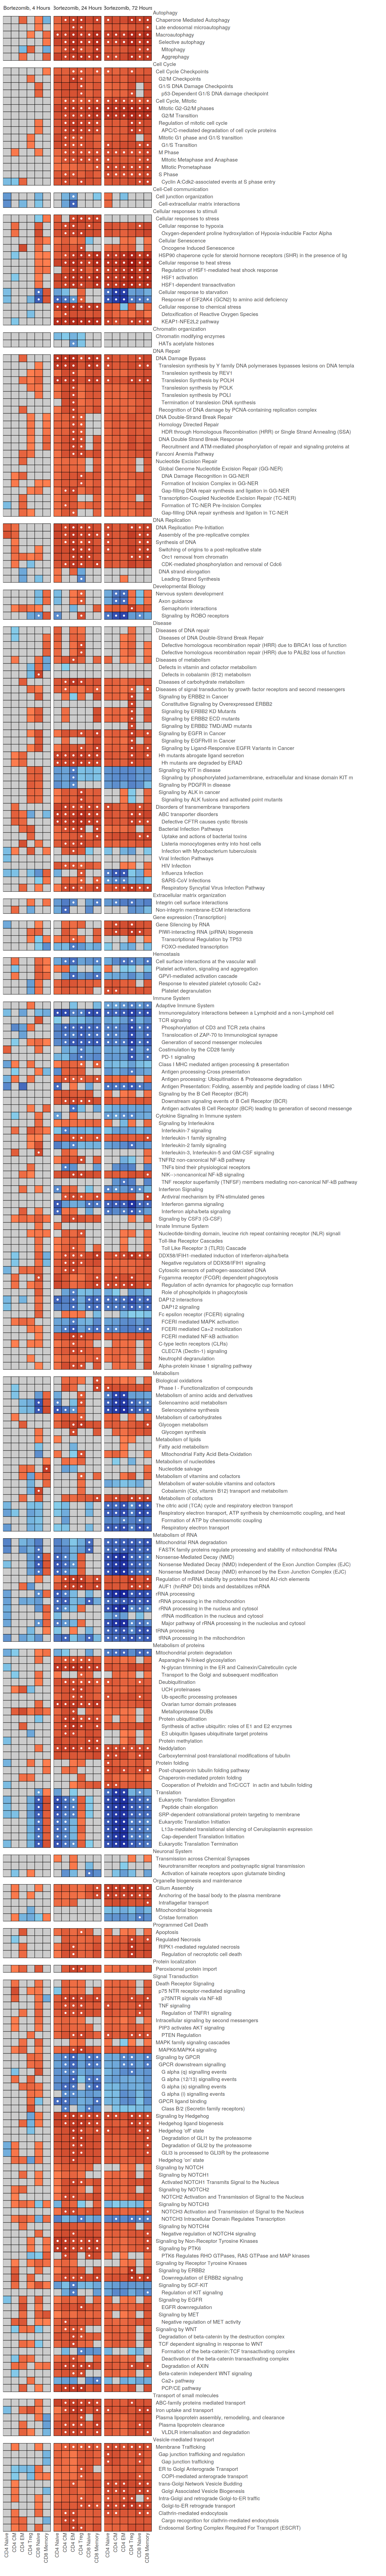

In [36]:
options(repr.plot.width = 12, repr.plot.height = 80)
reactome_heatmap <- ggplot() +
  geom_tile(
      data = missing_tiles,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black",
      fill = "gray80"
  ) +
  geom_tile(
      data = plot_data,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black") +
  geom_point(
      data = plot_data %>% filter(adjP < fdr_cutoff),
      aes(x = xpos,
          y = ypos),
      color = "white",
      size = 0.9) +
  scale_fill_identity() +
  scale_x_continuous(
      "",
      breaks = xpos_df$xpos,
      labels = xpos_df$cell_type_label,
      expand = c(0, 0)) +
  scale_y_continuous(
      "",
      breaks = ypos_df$ypos,
      labels = ypos_df$y_label,
      limits = range(ypos_df$ypos) + c(-0.5, 0),
      expand = c(0, 0),
      position = "right"
  ) +
  facet_wrap(~ timepoint_label) +
  theme_bw(base_size = 14) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.border = element_blank(),
        axis.ticks = element_blank(),
        strip.background = element_blank(),
        panel.grid = element_blank())
reactome_heatmap

In [37]:
heatmap_file <- file.path(
    out_dir,
    paste0("bortezomib_no-PSM_reactome_heatmap_",Sys.Date(),".pdf")
)
ggsave(heatmap_file,
       reactome_heatmap,
       width = 4.5, height = 4)

## Difference heatmap

In addition to an updated heatmap, it's also helpful to see the changes that occurred between the two result sets - with and without Proteasomal genes.

In [38]:
all_reactome <- read.table(reactome_file, sep = "\t", header = TRUE)

In [39]:
names(all_reactome)

[1] "fg"              "bg"              "timepoint"       "aifi_cell_type" 
 [5] "id"              "pathway"         "NES"             "nomP"           
 [9] "adjP"            "n_leadingEdge"   "n_pathway_genes" "leadingEdge"    
[13] "pathway_genes"

In [40]:
all_reactome %>%
  filter(id == "R-HSA-9664873")

fg,bg,timepoint,aifi_cell_type,id,pathway,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
bortezomib,dmso,72,t_cd4_treg,R-HSA-9664873,Pexophagy,1.711068,0.006757418,0.02950545,10,11,UBC;SQSTM1;UBB;MAP1LC3B,ATM;EPAS1 (HIF2A);MAP1LC3B;NBR1;PEX5;RPS27A;SQSTM1;UBA52;UBB;UBC;USP30


In [41]:
all_reactome <- all_reactome %>%
  filter(fg == "bortezomib") %>%
  select(-leadingEdge, -pathway_genes) %>%
  select(fg, timepoint, aifi_cell_type, id, pathway, adjP, NES) %>%
  rename(all_padj = adjP,
         all_NES = NES)

In [42]:
str(all_reactome)

'data.frame':	12611 obs. of  7 variables:
 $ fg            : chr  "bortezomib" "bortezomib" "bortezomib" "bortezomib" ...
 $ timepoint     : int  24 24 24 24 24 24 24 24 24 24 ...
 $ aifi_cell_type: chr  "t_cd4_cm" "t_cd4_cm" "t_cd4_cm" "t_cd4_cm" ...
 $ id            : chr  "R-HSA-8951664" "R-HSA-5619115" "R-HSA-9755511" "R-HSA-453274" ...
 $ pathway       : chr  "Neddylation" "Disorders of transmembrane transporters" "KEAP1-NFE2L2 pathway" "Mitotic G2-G2/M phases" ...
 $ all_padj      : num  5.86e-19 9.07e-17 9.18e-16 6.29e-16 1.51e-15 ...
 $ all_NES       : num  2.37 2.35 2.34 2.34 2.33 ...


In [43]:
no_psm_reactome <- gsea_res %>%
  select(-leadingEdge, -pathway_genes) %>%
  select(fg, timepoint, aifi_cell_type, id, pathway, adjP, NES) %>%
  rename(no_psm_padj = adjP,
         no_psm_NES = NES)

In [44]:
str(no_psm_reactome)

'data.frame':	12176 obs. of  7 variables:
 $ fg            : chr  "bortezomib" "bortezomib" "bortezomib" "bortezomib" ...
 $ timepoint     : int  24 24 24 24 24 24 24 24 24 24 ...
 $ aifi_cell_type: chr  "t_cd4_cm" "t_cd4_cm" "t_cd4_cm" "t_cd4_cm" ...
 $ id            : chr  "R-HSA-9755511" "R-HSA-9711123" "R-HSA-73893" "R-HSA-110313" ...
 $ pathway       : chr  "KEAP1-NFE2L2 pathway" "Cellular response to chemical stress" "DNA Damage Bypass" "Translesion synthesis by Y family DNA polymerases bypasses lesions on DNA template" ...
 $ no_psm_padj   : num  4.56e-05 6.07e-05 7.07e-04 6.98e-04 1.30e-03 ...
 $ no_psm_NES    : num  2.13 2.07 2.06 2.05 2.03 ...


In [45]:
joint_gsea <- all_reactome %>%
  left_join(no_psm_reactome) %>%
  left_join(type_colors) %>%
  left_join(reactome_names) %>%
  mutate(diff = no_psm_NES - all_NES,
         abs_diff = abs(diff)) %>%
  mutate(all_sig = all_padj < 0.05,
         no_psm_sig = no_psm_padj < 0.05) %>%
  mutate(sig_change = all_sig & !no_psm_sig)

Joining with `by = join_by(fg, timepoint, aifi_cell_type, id, pathway)`
Joining with `by = join_by(aifi_cell_type)`
Joining with `by = join_by(id)`


In [46]:
joint_gsea <- joint_gsea %>%
  filter(pathway_depth <= max_depth)

In [47]:
head(joint_gsea)

,fg,timepoint,aifi_cell_type,id,pathway,all_padj,all_NES,no_psm_padj,no_psm_NES,cell_type_label,⋯,cell_type_xpos,cell_type_ypos,pathway_name,pathway_depth,pathway_label,diff,abs_diff,all_sig,no_psm_sig,sig_change
,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,⋯,<int>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>,<lgl>
1,bortezomib,24,t_cd4_cm,R-HSA-8951664,Neddylation,5.864681e-19,2.370750,9.677046e-04,1.939849,CD4 CM,⋯,2,6,Neddylation,l2,l2_Neddylation,-0.4309017,0.4309017,TRUE,TRUE,FALSE
2,bortezomib,24,t_cd4_cm,R-HSA-5619115,Disorders of transmembrane transporters,9.068432e-17,2.346760,4.873900e-03,1.954878,CD4 CM,⋯,2,6,Disorders of transmembrane transporters,l1,l1_Disorders of transmembrane transporters,-0.3918814,0.3918814,TRUE,TRUE,FALSE
3,bortezomib,24,t_cd4_cm,R-HSA-9755511,KEAP1-NFE2L2 pathway,9.175604e-16,2.344083,4.561941e-05,2.134859,CD4 CM,⋯,2,6,KEAP1-NFE2L2 pathway,l3,l3_KEAP1-NFE2L2 pathway,-0.2092234,0.2092234,TRUE,TRUE,FALSE
4,bortezomib,24,t_cd4_cm,R-HSA-453274,Mitotic G2-G2/M phases,6.288776e-16,2.342449,6.103092e-03,1.885463,CD4 CM,⋯,2,6,Mitotic G2-G2/M phases,l2,l2_Mitotic G2-G2/M phases,-0.4569861,0.4569861,TRUE,TRUE,FALSE
5,bortezomib,24,t_cd4_cm,R-HSA-69275,G2/M Transition,1.507501e-15,2.334710,1.295191e-02,1.832232,CD4 CM,⋯,2,6,G2/M Transition,l3,l3_G2/M Transition,-0.5024776,0.5024776,TRUE,TRUE,FALSE
6,bortezomib,24,t_cd4_cm,R-HSA-5688426,Deubiquitination,2.412160e-16,2.323588,1.351767e-02,1.784479,CD4 CM,⋯,2,6,Deubiquitination,l2,l2_Deubiquitination,-0.5391095,0.5391095,TRUE,TRUE,FALSE


In [48]:
change_data <- file.path(
    out_dir,
    paste0("bortezomib_no-PSM_reactome_difference_data_",Sys.Date(),".csv")
)
write.csv(
    joint_gsea,
    change_data,
    quote = FALSE,
    row.names = FALSE
)

In [49]:
sig_change_gsea <- joint_gsea %>%
  #filter(all_sig | no_psm_sig)
  filter(all_sig)
sig_change_pathways <- reactome_order %>%
  filter(name %in% sig_change_gsea$pathway)

In [50]:
sig_change_gsea %>%
  filter(id == "R-HSA-9664873")

fg,timepoint,aifi_cell_type,id,pathway,all_padj,all_NES,no_psm_padj,no_psm_NES,cell_type_label,⋯,cell_type_xpos,cell_type_ypos,pathway_name,pathway_depth,pathway_label,diff,abs_diff,all_sig,no_psm_sig,sig_change
<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,⋯,<int>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>,<lgl>
bortezomib,72,t_cd4_treg,R-HSA-9664873,Pexophagy,0.02950545,1.711068,0.05013904,1.796067,CD4 Treg,⋯,4,4,Pexophagy,l3,l3_Pexophagy,0.0849989,0.0849989,TRUE,FALSE,TRUE


In [51]:
head(sig_change_pathways)

,id,name,pathway_depth,root_order,l1_order,l2_order,l3_order,l4_order,set_order,pathway_label
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
1,R-HSA-9613829,Chaperone Mediated Autophagy,l1,1,1,0,0,0,2,l1_Chaperone Mediated Autophagy
2,R-HSA-9615710,Late endosomal microautophagy,l1,1,2,0,0,0,3,l1_Late endosomal microautophagy
3,R-HSA-1632852,Macroautophagy,l1,1,3,0,0,0,4,l1_Macroautophagy
4,R-HSA-9663891,Selective autophagy,l2,1,3,1,0,0,5,l2_Selective autophagy
5,R-HSA-5205647,Mitophagy,l3,1,3,1,1,0,6,l3_Mitophagy
6,R-HSA-9646399,Aggrephagy,l3,1,3,1,2,0,9,l3_Aggrephagy


In [52]:
nrow(sig_pathways)

[1] 280

In [53]:
nrow(sig_change_pathways)

[1] 310

In [54]:
parent_pathways <- map_dfr(
    1:nrow(sig_change_pathways),
    function(i) {
        row_l1 <- sig_change_pathways$l1_order[i]
        row_l2 <- sig_change_pathways$l2_order[i]
        row_l3 <- sig_change_pathways$l3_order[i]
        row_l4 <- sig_change_pathways$l4_order[i]
        
        if(row_l2 > 0) {
            l1_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == 0 & l3_order == 0 & l4_order == 0)
        } else {
            l1_row <- reactome_order[0,]
        }
        
        if(row_l3 > 0) {
            l2_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == row_l2 & l3_order == 0 & l4_order == 0)
        } else {
            l2_row <- reactome_order[0,]
        }
        
        if(row_l4 > 0) {
            l3_row <- reactome_order %>%
              filter(l1_order == row_l1 & l2_order == row_l2 & l3_order == row_l3 & l4_order == 0)
        } else {
            l3_row <- reactome_order[0,]
        }
        rbind(l1_row, l2_row, l3_row)
    }
)
parent_pathways <- unique(parent_pathways)

In [55]:
head(parent_pathways)

,id,name,pathway_depth,root_order,l1_order,l2_order,l3_order,l4_order,set_order,pathway_label
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
1,R-HSA-1632852,Macroautophagy,l1,1,3,0,0,0,4,l1_Macroautophagy
3,R-HSA-9663891,Selective autophagy,l2,1,3,1,0,0,5,l2_Selective autophagy
8,R-HSA-69620,Cell Cycle Checkpoints,l1,2,4,0,0,0,12,l1_Cell Cycle Checkpoints
11,R-HSA-69615,G1/S DNA Damage Checkpoints,l2,2,4,3,0,0,17,l2_G1/S DNA Damage Checkpoints
14,R-HSA-69278,"Cell Cycle, Mitotic",l1,2,5,0,0,0,27,"l1_Cell Cycle, Mitotic"
16,R-HSA-453274,Mitotic G2-G2/M phases,l2,2,5,5,0,0,28,l2_Mitotic G2-G2/M phases


In [56]:
parent_data <- joint_gsea %>%
  filter(pathway_label %in% parent_pathways$pathway_label)
plot_data <- joint_gsea %>%
  filter(pathway %in% sig_change_gsea$pathway)
plot_data <- rbind(plot_data, parent_data)

In [57]:
pad <- function(n) {
    paste(rep(" ",n), collapse = "")
}

In [58]:
ypos_df <- plot_data %>%
  select(pathway_label) %>%
  unique() %>%
  left_join(reactome_order) %>%
  arrange(set_order) %>%
  mutate(y_order = n():1) %>%
  mutate(y_label = case_when(
      grepl("^l1", pathway_label) ~ sub("l1_", pad(2), pathway_label),
      grepl("^l2", pathway_label) ~ sub("l2_", pad(4), pathway_label),
      grepl("^l3", pathway_label) ~ sub("l3_", pad(6), pathway_label),
      grepl("^l4", pathway_label) ~ sub("l4_", pad(8), pathway_label),
      TRUE ~ pathway_label
  ))

root_offset <- ypos_df %>%
  select(root_order) %>%
  unique() %>%
  mutate(y_offset = n():1)

ypos_df <- ypos_df %>%
  left_join(root_offset) %>%
  mutate(ypos = y_order + y_offset)

root_labels <- ypos_df %>%
  group_by(root_order) %>%
  filter(ypos == max(ypos)) %>%
  ungroup() %>%
  mutate(ypos = ypos + 1) %>%
  select(root_order, ypos) %>%
  left_join(root_order) %>%
  mutate(pathway_label = paste0("root_", name),
         y_order = 0,
         set_order = 0,
         y_offset = 0,
         y_label = name) %>%
  select(one_of(names(ypos_df)))

ypos_df <- rbind(ypos_df, root_labels) %>%
  arrange(desc(ypos))

timepoint_df <- data.frame(
    timepoint = c(4, 24, 72),
    timepoint_label = factor(c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"), 
                             levels = c("Bortezomib, 4 Hours", "Bortezomib, 24 Hours", "Bortezomib, 72 Hours"))
)

Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(root_order)`
Joining with `by = join_by(root_order)`


In [59]:
str(gc_df)

'data.frame':	601 obs. of  2 variables:
 $ NES      : chr  "-3" "-2.99" "-2.98" "-2.97" ...
 $ nes_color: chr  "#00008B" "#00018B" "#01028B" "#02038C" ...


In [60]:
plot_data <- plot_data %>%
  left_join(xpos_df) %>%
  left_join(ypos_df)

Joining with `by = join_by(cell_type_label, cell_type_xpos)`
Joining with `by = join_by(id, pathway_depth, pathway_label)`


In [61]:
change_plot_data <- plot_data %>%
  filter(sig_change)

In [62]:
sig_plot_data <- plot_data %>%
  filter(all_sig & no_psm_sig)

In [63]:
missing_tiles <- expand.grid(
    xpos = unique(plot_data$xpos),
    ypos = unique(plot_data$ypos),
    timepoint = unique(plot_data$timepoint)
)
missing_tiles <- missing_tiles %>%
  filter(
      !paste(xpos, ypos, timepoint) %in%
      paste(plot_data$xpos, plot_data$ypos, plot_data$timepoint)
  )

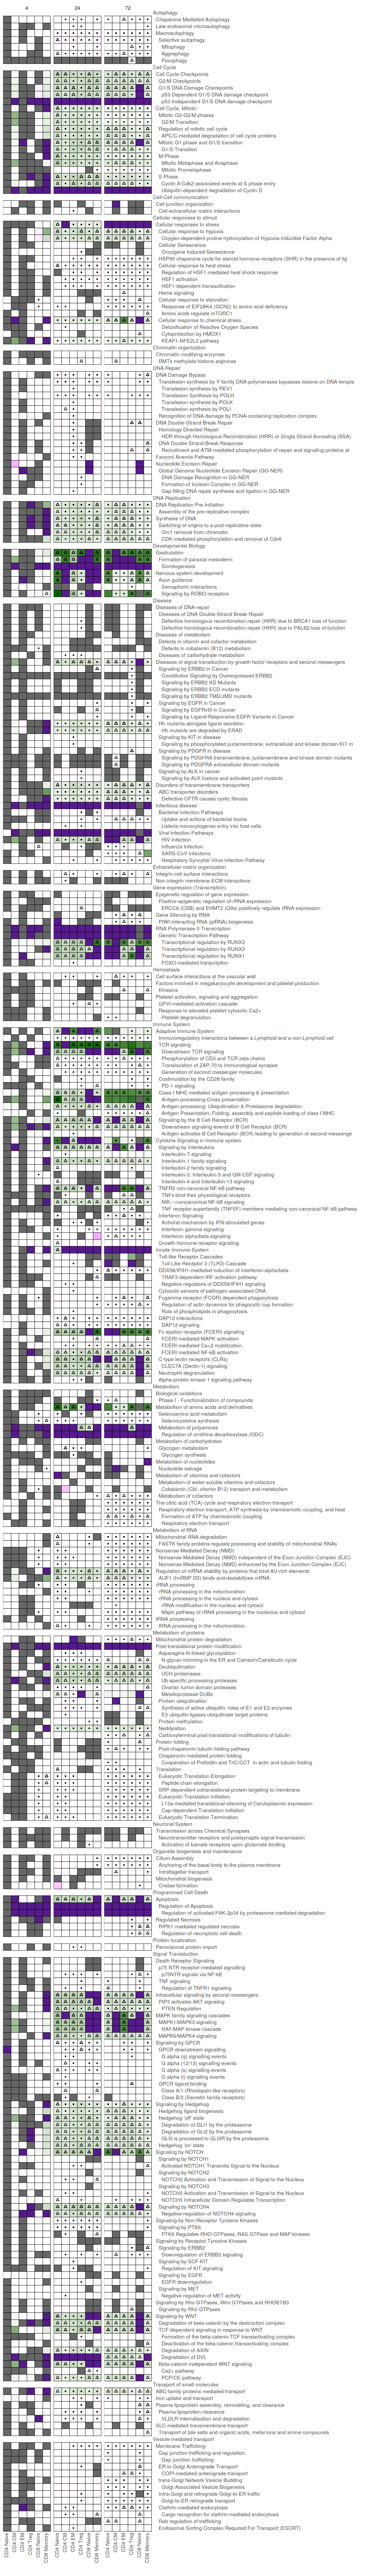

In [74]:
options(repr.plot.width = 12, repr.plot.height = 80)
change_plot <- ggplot() +
    geom_tile(
      data = missing_tiles,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black",
      fill = "gray40"
  ) +
  geom_tile(
      data = plot_data,
      aes(x = cell_type_xpos,
          y = ypos,
          fill = diff),
      color = "black"
  ) +
  geom_point(
      data = change_plot_data,
      aes(x = cell_type_xpos,
          y = ypos),
      pch = 2,
      color = "black"
  ) +
  geom_point(
      data = sig_plot_data,
      aes(x = cell_type_xpos,
          y = ypos),
      size = 0.4
  ) +
  # geom_point(
  #     data = gain_plot_data,
  #     aes(x = cell_type_xpos,
  #         y = ypos),
  #     pch = 3,
  #     color = "black"
  # ) +
  scale_fill_gradient2(
      low = "darkgreen",
      mid = "white",
      high = "magenta",
      midpoint = 0,
      na.value = "purple4"
  ) +
  scale_x_continuous(
      "",
      breaks = type_colors$cell_type_xpos,
      labels = type_colors$cell_type_label,
      expand = c(0,0)
  ) +
  scale_y_continuous(
      "",
      breaks = ypos_df$ypos,
      labels = ypos_df$y_label,
      limits = range(ypos_df$ypos) + c(-0.5, 0),
      expand = c(0, 0),
      position = "right"
  ) +
  facet_wrap(
      ~timepoint,
      ncol = 3
  ) +
  theme_bw(base_size = 14) +
  theme(panel.grid = element_blank(),
        axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        axis.ticks = element_blank(),
        panel.border = element_blank(),
        strip.background = element_blank(),
        legend.position = "none"
       )
change_plot

In [75]:
change_file <- file.path(
    out_dir,
    paste0("bortezomib_no-PSM_reactome_differences_",Sys.Date(),".pdf")
)
suppressWarnings(
    ggsave(change_file,
           change_plot,
           width = 12, height = 80,
          limitsize = FALSE)
)

# Store results in HISE

Finally, we store the output file in our Collaboration Space for later retrieval and use. We need to provide the UUID for our Collaboration Space (aka `studySpaceId`), as well as a title for this step in our analysis process.

The hise function `uploadFiles()` also requires the FileIDs from the original fileset for reference.

In [64]:
study_space_uuid <- "40df6403-29f0-4b45-ab7d-f46d420c422e"
title <- paste("VRd TEA-seq Supp Fig Bor Reactome No PSM changes l1-l3", Sys.Date())

In [65]:
out_list <- as.list(c(heatmap_file, change_data, change_file))

In [66]:
out_list

[[1]]
[1] "output/supp_figure_06/bortezomib_no-PSM_reactome_heatmap_2026-10-05.pdf"

[[2]]
[1] "output/supp_figure_06/bortezomib_no-PSM_reactome_difference_data_2026-10-05.csv"

[[3]]
[1] "output/supp_figure_06/bortezomib_no-PSM_reactome_differences_2026-10-05.pdf"

In [67]:
in_list <- c(reactome_uuid, no_psm_uuid)

In [68]:
sessionInfo()

R version 4.4.1 (2024-06-14)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/workspace/environment/archrpixiv12/.pixi/envs/default/lib/libopenblasp-r0.3.33.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C          
 [4] LC_COLLATE=C        LC_MONETARY=C       LC_MESSAGES=C      
 [7] LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C       
[10] LC_TELEPHONE=C      LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] cowplot_1.2.0 ggplot2_4.0.3 dplyr_1.2.1   purrr_1.2.2   hise_3.6.15  

loaded via a namespace (and not attached):
 [1] gtable_0.3.6       jsonlite_2.0.0     compiler_4.4.1     crayon_1.5.3      
 [5] Rcpp_1.1.1-1.1     tidyselect_1.2.1   IRdisplay_1.1      bitops_1.0-9      
 [9] assertthat_0

In [69]:
uploadFiles(
    files = out_list,
    studySpaceId = study_space_uuid,
    title = title,
    inputFileIds = in_list,
    store = "project",
    doPrompt = FALSE
)

[2026-10-05 10:09:30] INFO  Calling uploadFiles
[2026-10-05 10:10:12] INFO  Finished uploadFiles successfully (time_elapsed=38.050s)


$Message
[1] "General Okay-ness"

$VisualizationId
[1] "00000000-0000-0000-0000-000000000000"

$AbstractionId
[1] "00000000-0000-0000-0000-000000000000"

$TraceId
[1] "33064491-cecc-4081-a2f5-242600c662b0"

$ProcessId
[1] "9eaf9736-1a5a-46ab-8d54-c1b73ea6e191"

$WorkflowId
[1] "772013f7-4f63-4e1c-ad5f-3f88e3c45dee"

$FileIds
$FileIds[[1]]
[1] "3c4c683e-08ac-4014-8159-5a99d28c41ed"

$FileIds[[2]]
[1] "24394fa0-a888-49cf-a85a-f46e081902d3"

$FileIds[[3]]
[1] "b999ac4e-b084-4418-9a65-74b0f6121d1c"